# Pretraining curves (model overview)

Reads `../data/pretraining_curves.tsv` and writes **one figure per metric** to
`../output/` (`.pdf`, `.png`, `.svg`, and a source-data `.tsv`).

The table is frozen once by `../pretraining_curves_data.py`; this
notebook only loads it and plots — one metric per figure, never combined.

In [1]:
from pathlib import Path
import sys

# Self-contained: works from notebook/, the group folder, or the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)

DATA: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/data
OUT : /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

curves = pd.read_csv(DATA / "pretraining_curves.tsv", sep="\t")
step_k = curves["step"].to_numpy() / 1000.0  # steps in units of 10^3

def plot_curve(col, title, ylabel, sigma, stem):
    """Plot one pretraining metric as its own figure (raw + Gaussian-smoothed)."""
    raw = curves[col].to_numpy()
    smooth = gaussian_filter1d(raw, sigma=sigma)

    fig, ax = plt.subplots(figsize=(2.4, 1.9))
    ax.plot(step_k, raw, color=OKABE_ITO["blue"], alpha=0.20, linewidth=0.4, zorder=1)
    ax.plot(step_k, smooth, color=OKABE_ITO["blue"], linewidth=1.0, zorder=2)
    ax.scatter(step_k[-1], smooth[-1], color=OKABE_ITO["blue"], s=12, zorder=3)
    ax.annotate(f"{smooth[-1]:.2f}", xy=(step_k[-1], smooth[-1]),
                xytext=(-3, 3), textcoords="offset points", ha="right", fontsize=6)
    ax.set_xlabel("Step (\u00d710\u00b3)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    fig.tight_layout()

    data = pd.DataFrame({"step": curves["step"], f"{col}_raw": raw, f"{col}_smooth": smooth})
    savefig(fig, OUT, stem, data=data)
    plt.show()

print(f"loaded {len(curves)} steps; columns: {list(curves.columns)}")

loaded 520 steps; columns: ['step', 'loss', 'token_accuracy', 'recall', 'mcc']


saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_loss.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_loss.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_loss.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_loss.tsv


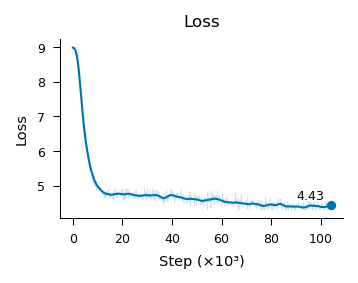

In [3]:
# Loss
plot_curve("loss", "Loss", "Loss", sigma=5, stem="pretraining_loss")

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_token_accuracy.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_token_accuracy.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_token_accuracy.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_token_accuracy.tsv


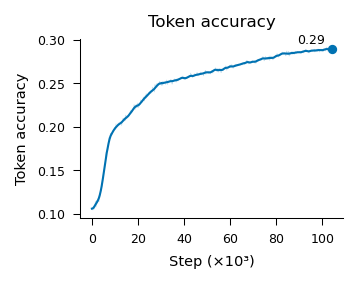

In [4]:
# Token accuracy
plot_curve("token_accuracy", "Token accuracy", "Token accuracy", sigma=3, stem="pretraining_token_accuracy")

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_recall.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_recall.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_recall.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_recall.tsv


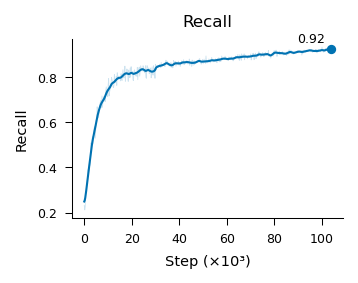

In [5]:
# Recall
plot_curve("recall", "Recall", "Recall", sigma=3, stem="pretraining_recall")

saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_mcc.pdf
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_mcc.png
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_mcc.svg
saved: /home/hamedh/projects/fragmentomics/multi_modal_fragments/bert_window_embedding/draft/leaf-1-figures/other/output/pretraining_mcc.tsv


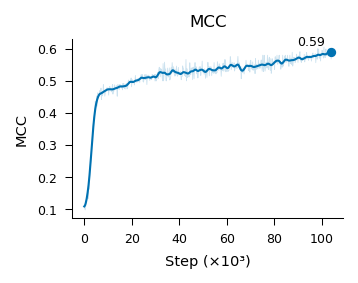

In [6]:
# MCC
plot_curve("mcc", "MCC", "MCC", sigma=3, stem="pretraining_mcc")